In [2]:
!pwd
!ls

/content
gia_nha.csv  hai_vang_trang.csv  sample_data  sinh_vien_mo_rong.csv


In [5]:
import pandas as pd
import os

print("Các file hiện có:")
print(os.listdir('/content'))

df = pd.read_csv('/content/sinh_vien_mo_rong.csv')
display(df.head())
print(df.info())

Các file hiện có:
['.config', 'gia_nha.csv', 'hai_vang_trang.csv', 'sinh_vien_mo_rong.csv', 'sample_data']


,gio_on,diem_giua_ky,chi_tieu,qua_mon
0,5.5,3.0,5050,0
1,19.0,6.0,7700,1
2,14.0,7.7,2850,0
3,11.0,3.1,7700,0
4,10.5,5.8,3850,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   gio_on        120 non-null    float64
 1   diem_giua_ky  120 non-null    float64
 2   chi_tieu      120 non-null    int64  
 3   qua_mon       120 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 3.9 KB
None


Kết quả dự đoán cho bạn mới (12 giờ ôn, 6.5 điểm): Qua môn
Xác suất: Rớt môn: 0.0%, Qua môn: 100.0%


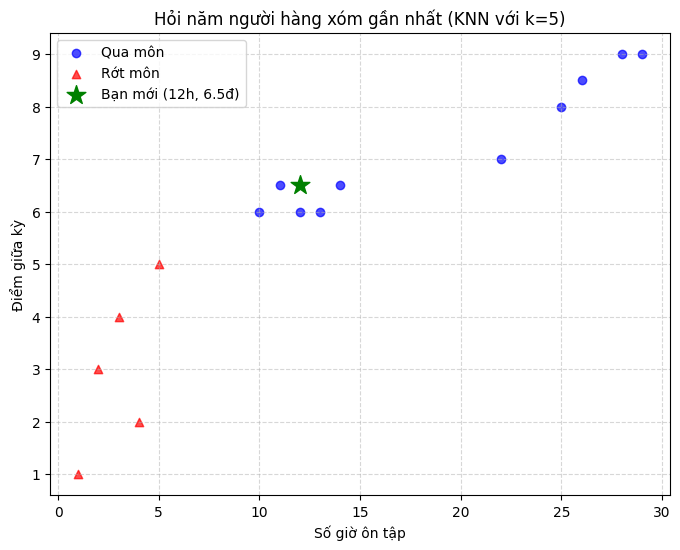

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier

X_train = np.array([
    [10, 6], [11, 6.5], [12, 6], [13, 6], [14, 6.5],
    [2, 3], [3, 4], [4, 2], [5, 5], [1, 1],
    [25, 8], [28, 9], [22, 7], [26, 8.5], [29, 9]
])

y_train = np.array([1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1])

k = 5
knn = KNeighborsClassifier(n_neighbors=k)

knn.fit(X_train, y_train)

X_new = np.array([[12, 6.5]])
prediction = knn.predict(X_new)
probabilities = knn.predict_proba(X_new)

print(f"Kết quả dự đoán cho bạn mới (12 giờ ôn, 6.5 điểm): {'Qua môn' if prediction[0] == 1 else 'Rớt môn'}")
print(f"Xác suất: Rớt môn: {probabilities[0][0]*100:.1f}%, Qua môn: {probabilities[0][1]*100:.1f}%")

plt.figure(figsize=(8, 6))
plt.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1], color='blue', alpha=0.7, label='Qua môn')
plt.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1], color='red', marker='^', alpha=0.7, label='Rớt môn')
plt.scatter(X_new[0, 0], X_new[0, 1], color='green', marker='*', s=200, label='Bạn mới (12h, 6.5đ)')

plt.xlabel('Số giờ ôn tập')
plt.ylabel('Điểm giữa kỳ')
plt.title('Hỏi năm người hàng xóm gần nhất (KNN với k=5)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [12]:


import numpy as np
import pandas as pd

ba_ban = {
    "A": np.array([5.0, 2.0, 4000.0]),
    "B": np.array([25.0, 9.0, 4100.0]),
    "C": np.array([6.0, 3.5, 7000.0]),
}


def kc(u, v):
    """Khoang cach Euclid giua hai diem."""
    return np.sqrt(((u - v) ** 2).sum())


print("Khoang cach KHI CHUA chuan hoa")
print(f"d(A, B) = {kc(ba_ban['A'], ba_ban['B']):.1f}")
print(f"d(A, C) = {kc(ba_ban['A'], ba_ban['C']):.1f}")
print()

df = pd.read_csv("sinh_vien_mo_rong.csv")
X = df[["gio_on", "diem_giua_ky", "chi_tieu"]].to_numpy(dtype=float)
tb = X.mean(axis=0)
dl = X.std(axis=0)
print("Do lech chuan cua ba cot:")
print(f"  gio_on ({dl[0]:.2f})  diem_giua_ky ({dl[1]:.2f})")
print(f"  chi_tieu ({dl[2]:.0f})")
print()

chuan = {ten: (x - tb) / dl for ten, x in ba_ban.items()}
print("Khoang cach SAU KHI chuan hoa")
print(f"d(A, B) = {kc(chuan['A'], chuan['B']):.2f}")
print(f"d(A, C) = {kc(chuan['A'], chuan['C']):.2f}")
print()

X2 = df[["gio_on", "diem_giua_ky"]].to_numpy(dtype=float)
y = df["qua_mon"].to_numpy()
tb2, dl2 = X2.mean(axis=0), X2.std(axis=0)
ban_moi = np.array([12.0, 6.5])
X2c = (X2 - tb2) / dl2
moi_c = (ban_moi - tb2) / dl2
khoang = np.sqrt(((X2c - moi_c) ** 2).sum(axis=1))
gan = np.argsort(khoang)[:5]

print("Ban moi: on 12 gio, diem giua ky 6.5")
print("5 nam lang gieng gan nhat:")
for i in gan:
    ket = "qua" if y[i] == 1 else "rot"
    print(
        f"  gio {X2[i, 0]:5.1f}  diem {X2[i, 1]:6.1f} "
        f"-> khoang cach {khoang[i]:.3f}  -> {ket}"
    )

so_qua = int(y[gan].sum())
print(f"So qua phieu: {so_qua} qua, {5 - so_qua} rot")
print(f"Du doan: {'qua mon' if so_qua >= 3 else 'rot mon'}")

Khoang cach KHI CHUA chuan hoa
d(A, B) = 102.2
d(A, C) = 3000.0

Do lech chuan cua ba cot:
  gio_on (7.82)  diem_giua_ky (2.09)
  chi_tieu (1692)

Khoang cach SAU KHI chuan hoa
d(A, B) = 4.21
d(A, C) = 1.92

Ban moi: on 12 gio, diem giua ky 6.5
5 nam lang gieng gan nhat:
  gio  10.5  diem    6.4 -> khoang cach 0.198  -> qua
  gio  12.5  diem    6.1 -> khoang cach 0.202  -> qua
  gio  14.0  diem    6.4 -> khoang cach 0.260  -> qua
  gio   9.5  diem    6.1 -> khoang cach 0.373  -> rot
  gio  10.5  diem    5.8 -> khoang cach 0.386  -> qua
So qua phieu: 4 qua, 1 rot
Du doan: qua mon


In [13]:


import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("sinh_vien_mo_rong.csv")
y = df["qua_mon"]

X3 = df[["gio_on", "diem_giua_ky", "chi_tieu"]]
X_tr, X_te, y_tr, y_te = train_test_split(
    X3, y, test_size=0.25, random_state=17, stratify=y
)


def cham(mo_hinh, cot):
    mo_hinh.fit(X_tr[cot], y_tr)
    return accuracy_score(y_te, mo_hinh.predict(X_te[cot]))


def knn_chuan():
    """KNN co chuan hoa, gop lam mot khoi bang pipeline."""
    return make_pipeline(StandardScaler(), KNeighborsClassifier(7))


ba_cot = ["gio_on", "diem_giua_ky", "chi_tieu"]
hai_cot = ["gio_on", "diem_giua_ky"]

a = cham(KNeighborsClassifier(n_neighbors=7), ba_cot)
b = cham(knn_chuan(), ba_cot)
c = cham(knn_chuan(), hai_cot)

print(f"Doan bua ca lop qua          : {y_te.mean():.4f}")
print(f"Ba cot, khong chuan hoa      : {a:.4f}")
print(f"Ba cot, co chuan hoa         : {b:.4f}")
print(f"Bo cot chi_tieu, co chuan hoa: {c:.4f}")

Doan bua ca lop qua          : 0.6000
Ba cot, khong chuan hoa      : 0.5333
Ba cot, co chuan hoa         : 0.8667
Bo cot chi_tieu, co chuan hoa: 0.9000


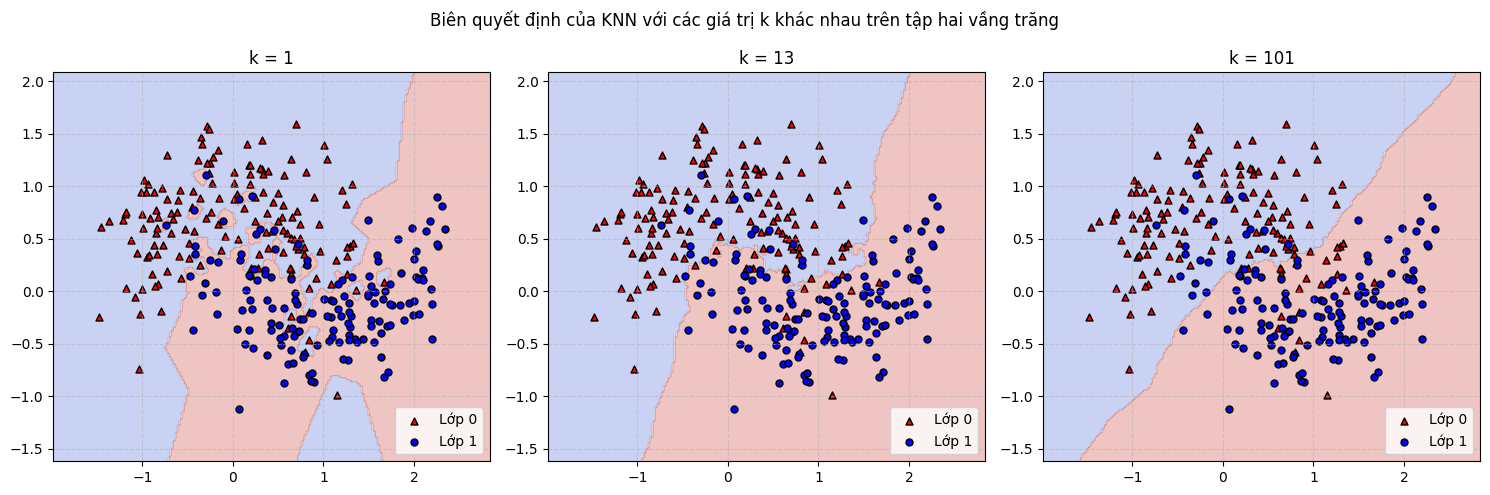

In [14]:


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("hai_vang_trang.csv")

X = df[["x1", "x2"]].to_numpy(dtype=float)

y = df.iloc[:, -1].to_numpy()

k_list = [1, 13, 101]

x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200)
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for idx, k in enumerate(k_list):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X, y)

    Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax = axes[idx]
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    ax.scatter(
        X[y == 0, 0],
        X[y == 0, 1],
        color="red",
        marker="^",
        edgecolor="k",
        s=25,
        label="Lớp 0",
    )
    ax.scatter(
        X[y == 1, 0],
        X[y == 1, 1],
        color="blue",
        marker="o",
        edgecolor="k",
        s=25,
        label="Lớp 1",
    )

    ax.set_title(f"k = {k}")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="lower right")

plt.suptitle(
    "Biên quyết định của KNN với các giá trị k khác nhau trên tập hai vầng trăng"
)
plt.tight_layout()
plt.show()

In [15]:


import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("Accuracy tren tap hoc va tap kiem tra theo k")
print("  k   tap hoc   tap kiem tra")

for k in [1, 5, 13, 31, 101]:
    mh = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
    a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
    a_kt = accuracy_score(y_te, mh.predict(X_te))
    print(f"{k:3d}   {a_hoc:.4f}     {a_kt:.4f}")

print()

print("Kiem dinh cheo 5 phan tren tap hoc:")
diem = {}
for k in range(1, 52, 2):
    diem[k] = cross_val_score(
        KNeighborsClassifier(n_neighbors=k), X_tr, y_tr, cv=5
    ).mean()

k_tot = max(diem, key=diem.get)

for k in [1, 5, 9, 13, 17, 25, 51]:
    dau = " <- tot nhat" if k == k_tot else ""
    print(f"  k = {k:2d}  diem trung binh {diem[k]:.4f}{dau}")

print()

mh = KNeighborsClassifier(n_neighbors=k_tot).fit(X_tr, y_tr)
print(f"k tot nhat = {k_tot}")
acc = accuracy_score(y_te, mh.predict(X_te))
print(f"Accuracy tren tap kiem tra = {acc:.4f}")

Accuracy tren tap hoc va tap kiem tra theo k
  k   tap hoc   tap kiem tra
  1   1.0000     0.8000
  5   0.8756     0.9067
 13   0.8844     0.9200
 31   0.8667     0.8933
101   0.8311     0.8533

Kiem dinh cheo 5 phan tren tap hoc:
  k =  1  diem trung binh 0.7778
  k =  5  diem trung binh 0.8444
  k =  9  diem trung binh 0.8444
  k = 13  diem trung binh 0.8667 <- tot nhat
  k = 17  diem trung binh 0.8533
  k = 25  diem trung binh 0.8622
  k = 51  diem trung binh 0.8533

k tot nhat = 13
Accuracy tren tap kiem tra = 0.9200


In [16]:


import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

cac_mo_hinh = [
    ("Hoi quy logistic", LogisticRegression()),
    ("Naive Bayes", GaussianNB()),
    ("KNN, k = 13", KNeighborsClassifier(n_neighbors=13)),
]

print("Accuracy tren tap kiem tra, bo hai vang trang")
for ten, mh in cac_mo_hinh:
    mh.fit(X_tr, y_tr)
    print(f"{ten}: {accuracy_score(y_te, mh.predict(X_te)):.4f}")

Accuracy tren tap kiem tra, bo hai vang trang
Hoi quy logistic: 0.8533
Naive Bayes: 0.8533
KNN, k = 13: 0.9200


In [19]:

import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor

df = pd.read_csv("gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42
)

knn = KNeighborsRegressor(n_neighbors=5).fit(X_tr, y_tr)
duong = LinearRegression().fit(X_tr, y_tr)

print("MAE tren tap kiem tra (ty dong)")
mae_knn = mean_absolute_error(y_te, knn.predict(X_te))
mae_duong = mean_absolute_error(y_te, duong.predict(X_te))
print(f"  KNN, k = 5 : {mae_knn:.4f}")
print(f"  Duong thang : {mae_duong:.4f}")
print()

can_moi = pd.DataFrame({"dien_tich": [60.0, 100.0, 150.0, 250.0]})
print("Du doan cho bon can moi (ty dong)")
print("  dien tich    KNN    duong thang")
for dt, a, b in zip(
    can_moi["dien_tich"], knn.predict(can_moi), duong.predict(can_moi)
):
    print(f"  {dt:6.0f} m2   {a:6.2f}   {b:6.2f}")
print()

_, chi_so = knn.kneighbors(pd.DataFrame({"dien_tich": [250.0]}))
lg = X_tr.iloc[chi_so[0]]["dien_tich"].tolist()
print("Nam lang gieng cua can 250 m2:", ", ".join(f"{v:.1f}" for v in lg))

MAE tren tap kiem tra (ty dong)
  KNN, k = 5 : 0.4030
  Duong thang : 0.2578

Du doan cho bon can moi (ty dong)
  dien tich    KNN    duong thang
      60 m2     4.95     5.12
     100 m2     8.32     8.24
     150 m2     9.32    12.13
     250 m2     9.32    19.91

Nam lang gieng cua can 250 m2: 117.5, 115.9, 111.7, 111.2, 104.2


In [20]:


import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("hai_vang_trang.csv")
X = df[["x1", "x2"]].to_numpy(dtype=float)
y = df["nhan"].to_numpy()

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)


def knn_du_doan(X_hoc, y_hoc, x_moi, k):
  khoang_cach = np.sqrt(((X_hoc - x_moi) ** 2).sum(axis=1))
  chi_so_gan = np.argsort(khoang_cach)[:k]
  nhan_gan = y_hoc[chi_so_gan]
  return 1 if nhan_gan.sum() >= (k / 2) else 0


k = 13
y_pred = [knn_du_doan(X_tr, y_tr, x, k) for x in X_te]
acc = accuracy_score(y_te, y_pred)
print(f"Bài 1 - Accuracy (k = 13): {acc:.4f}")

Bài 1 - Accuracy (k = 13): 0.9200


In [21]:


import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

diem = {}
for k in range(1, 52, 2):
  diem[k] = cross_val_score(
      KNeighborsClassifier(n_neighbors=k, metric="manhattan"), X_tr, y_tr, cv=5
  ).mean()

k_tot = max(diem, key=diem.get)
mh = KNeighborsClassifier(n_neighbors=k_tot, metric="manhattan").fit(
    X_tr, y_tr
)
acc = accuracy_score(y_te, mh.predict(X_te))
print(f"Bài 2 - k tốt nhất (Manhattan): {k_tot}, Accuracy: {acc:.4f}")

Bài 2 - k tốt nhất (Manhattan): 27, Accuracy: 0.9067


In [22]:


import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("sinh_vien_mo_rong.csv")
df["chi_tieu"] = df["chi_tieu"] / 1000
y = df["qua_mon"]
X3 = df[["gio_on", "diem_giua_ky", "chi_tieu"]]
X_tr, X_te, y_tr, y_te = train_test_split(
    X3, y, test_size=0.25, random_state=17, stratify=y
)

mh = KNeighborsClassifier(n_neighbors=7).fit(X_tr, y_tr)
acc = accuracy_score(y_te, mh.predict(X_te))
print(f"Bài 3 - Accuracy không chuẩn hóa (đổi đơn vị): {acc:.4f}")

Bài 3 - Accuracy không chuẩn hóa (đổi đơn vị): 0.8667


In [23]:


import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("Bài 4 - Accuracy với weights='distance':")
for k in [1, 13, 101]:
  mh = KNeighborsClassifier(n_neighbors=k, weights="distance").fit(X_tr, y_tr)
  acc = accuracy_score(y_te, mh.predict(X_te))
  print(f"  k = {k:3d} -> {acc:.4f}")

Bài 4 - Accuracy với weights='distance':
  k =   1 -> 0.8000
  k =  13 -> 0.9333
  k = 101 -> 0.9067


In [24]:


import pandas as pd
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsRegressor

df = pd.read_csv("gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42
)

diem = {}
for k in range(1, 21):
  scores = cross_val_score(
      KNeighborsRegressor(n_neighbors=k),
      X_tr,
      y_tr,
      cv=5,
      scoring="neg_mean_absolute_error",
  )
  diem[k] = scores.mean()

k_tot = max(diem, key=diem.get)
knn = KNeighborsRegressor(n_neighbors=k_tot).fit(X_tr, y_tr)
mae = mean_absolute_error(y_te, knn.predict(X_te))
print(f"Bài 5 - k tốt nhất: {k_tot}, MAE trên tập kiểm tra: {mae:.4f}")

Bài 5 - k tốt nhất: 2, MAE trên tập kiểm tra: 0.4867


In [25]:


import time
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

sizes = [1000, 10000, 100000]
print("Kích thước\tThời gian fit (s)\tThời gian predict (s)")

for size in sizes:
  rng = np.random.default_rng(0)
  X_hoc = rng.random((size, 2))
  y_hoc = rng.integers(0, 2, size)
  X_moi = rng.random((1000, 2))

  # Đo thời gian fit
  start = time.time()
  knn = KNeighborsClassifier(n_neighbors=5).fit(X_hoc, y_hoc)
  t_fit = time.time() - start

  # Đo thời gian predict cho 1000 mẫu mới
  start = time.time()
  knn.predict(X_moi)
  t_pred = time.time() - start

  print(f"{size:6d}\t\t{t_fit:.6f}\t\t{t_pred:.6f}")

Kích thước	Thời gian fit (s)	Thời gian predict (s)
  1000		0.006381		0.005353
 10000		0.005517		0.004676
100000		0.067855		0.006282


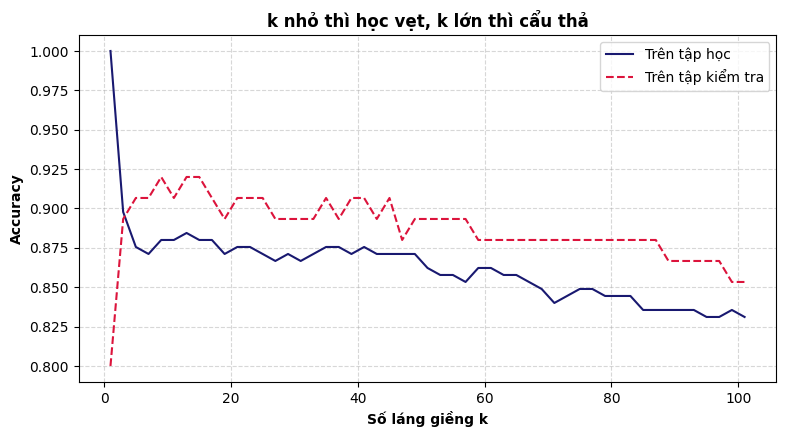

In [26]:


import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

k_range = range(1, 102, 2)
acc_hoc = []
acc_te = []

for k in k_range:
  mh = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
  acc_hoc.append(accuracy_score(y_tr, mh.predict(X_tr)))
  acc_te.append(accuracy_score(y_te, mh.predict(X_te)))

plt.figure(figsize=(9, 4.5))
plt.plot(
    list(k_range), acc_hoc, color="midnightblue", label="Trên tập học"
)
plt.plot(
    list(k_range),
    acc_te,
    color="crimson",
    linestyle="--",
    label="Trên tập kiểm tra",
)
plt.xlabel("Số láng giềng k", fontweight="bold")
plt.ylabel("Accuracy", fontweight="bold")
plt.title(
    "k nhỏ thì học vẹt, k lớn thì cẩu thả", fontsize=12, fontweight="bold"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

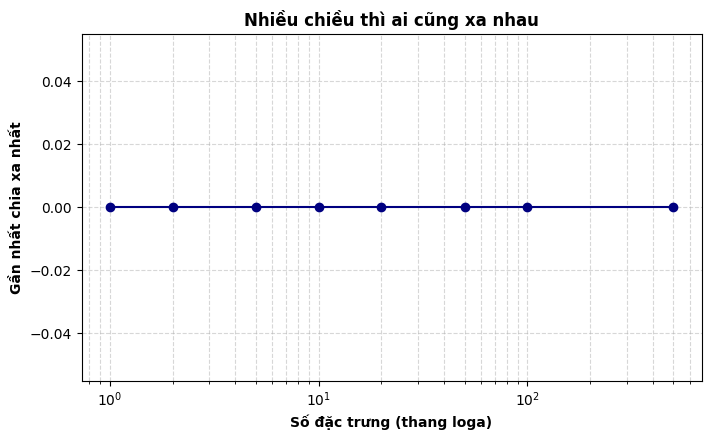

In [27]:


import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics.pairwise import euclidean_distances

n_points = 500
dimensions = [1, 2, 5, 10, 20, 50, 100, 500]
ratios = []

for dim in dimensions:
  rng = np.random.default_rng(0)
  X = rng.random((n_points, dim))
  dist_matrix = euclidean_distances(X, X)
  np.fill_diagonal(dist_matrix, np.inf)

  min_dists = dist_matrix.min(axis=1)
  max_dists = dist_matrix.max(axis=1)
  ratios.append((min_dists / max_dists).mean())

plt.figure(figsize=(8, 4.5))
plt.plot(dimensions, ratios, marker="o", color="navy", linewidth=1.5)
plt.xscale("log")
plt.xlabel("Số đặc trưng (thang loga)", fontweight="bold")
plt.ylabel("Gần nhất chia xa nhất", fontweight="bold")
plt.title("Nhiều chiều thì ai cũng xa nhau", fontsize=12, fontweight="bold")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.show()

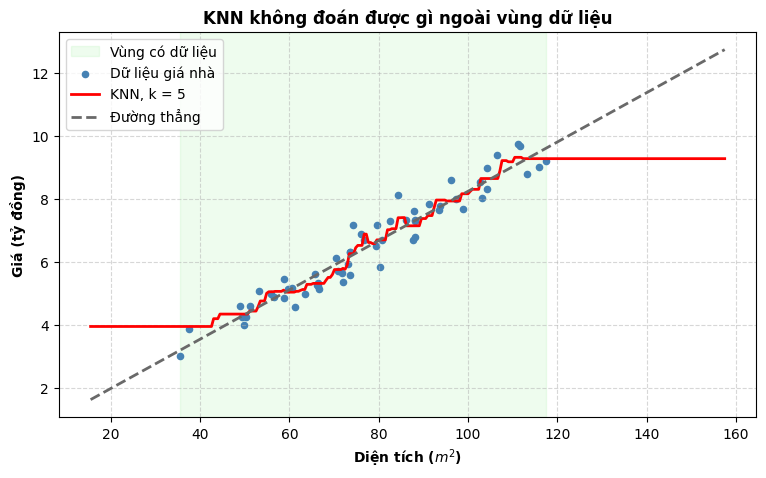

In [28]:


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor

df = pd.read_csv("gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]

knn = KNeighborsRegressor(n_neighbors=5).fit(X, y)
duong = LinearRegression().fit(X, y)

dien_tich_grid = np.linspace(
    X["dien_tich"].min() - 20, X["dien_tich"].max() + 40, 300
).reshape(-1, 1)
X_grid = pd.DataFrame(dien_tich_grid, columns=["dien_tich"])

y_knn_pred = knn.predict(X_grid)
y_duong_pred = duong.predict(X_grid)

plt.figure(figsize=(9, 5))
plt.axvspan(
    X["dien_tich"].min(),
    X["dien_tich"].max(),
    color="lightgreen",
    alpha=0.15,
    label="Vùng có dữ liệu",
)
plt.scatter(
    X["dien_tich"], y, color="steelblue", s=20, label="Dữ liệu giá nhà"
)
plt.plot(
    X_grid["dien_tich"],
    y_knn_pred,
    color="red",
    linewidth=2,
    label="KNN, k = 5",
)
plt.plot(
    X_grid["dien_tich"],
    y_duong_pred,
    color="dimgray",
    linestyle="--",
    linewidth=2,
    label="Đường thẳng",
)

plt.xlabel("Diện tích ($m^2$)", fontweight="bold")
plt.ylabel("Giá (tỷ đồng)", fontweight="bold")
plt.title(
    "KNN không đoán được gì ngoài vùng dữ liệu",
    fontsize=12,
    fontweight="bold",
)
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()